# Ablation V2 — CNN + Batch-Level GAT Baseline

## Prostate Cancer Detection · H&E Histopathology (DiagSet Binary)

**Journal Retrain — matched to Hybrid / LGCN / GAT / JGCN retrain protocol**

Purpose of V2: measure the contribution of the batch-level GAT branch on top of the CNN-only baseline (V1), *before* the SLIC-graph GCN or the SE-gated fusion are added. This is architecturally identical to "Hybrid minus GCN branch minus SE gate", so V2 vs V1 isolates the effect of adding the GAT branch under plain concatenation fusion.

- **Architecture**: EfficientNet-B4 (blocks 0-4 frozen) → cnn_proj (1792 → 512) + batch-level GAT branch (1792 → 256, 2 layers × 4 heads) → concat (512 + 256 = 768) → classifier (768 → 512 → 128 → 2)
- **No SLIC-graph GCN branch, no SE fusion gate.**
- **Local paths**: `<repo>/results\Ablation_V2\`
- **Environment**: `abide` conda env (torch 2.5.1+cu121, PyG 2.8.0, CUDA 12.1)
- **Hardware**: RTX 3060 12 GB

**Matched protocol vs V1 / Hybrid / LGCN / GAT / JGCN**
- 80 epochs, patience 15 on validation AUC-ROC
- Focal Loss (γ=2.0, α=0.75)
- AdamW differential LRs (backbone 1×10⁻⁴, head 3×10⁻⁴), weight decay 1×10⁻⁴
- CosineAnnealingWarmRestarts (T₀=10, T_mult=2)
- MixUp α=0.2 on 50% of batches, TrivialAugment, RandomErasing p=0.25
- WeightedRandomSampler, TTA×5 at inference (fp32)
- seed=42, image-level 70/15/15 stratified split (identical 901-patch test set)

**Artefacts produced (Cell 6B)**
- `v2_predictions.npz` — y_true / y_pred / y_prob (non-TTA & TTA) + 768-dim fused features
- `v2_history.json` — full epoch-by-epoch metrics
- `v2_env.json` — reproducibility fingerprint
- `checkpoints_backup/` — local copy of all four artefacts

**Bug fixes carried into V2**
- Val-loop probability/label lists renamed `v_probs, v_labels` (no more collision with dataset-level `all_labels`)
- Cell 6 reads test paths/labels directly from `test_ds` attributes


## CELL 1B — Local PC Setup

In [ ]:
# Resolve the repository root so this notebook runs from a clean clone.
import os
REPO_ROOT = os.getcwd()
while not os.path.exists(os.path.join(REPO_ROOT, 'config.py')):
    parent = os.path.dirname(REPO_ROOT)
    if parent == REPO_ROOT:
        raise RuntimeError('config.py not found - run this notebook from inside the repository')
    REPO_ROOT = parent
print('REPO_ROOT:', REPO_ROOT)


In [1]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 1B — Local PC Setup                                     ║
# ╚══════════════════════════════════════════════════════════════╝
import os

WORK_DIR   = os.path.join(REPO_ROOT, 'runs', 'ablation_v2')
DATA_ROOT  = REPO_ROOT
DRIVE_ROOT = DATA_ROOT

os.makedirs(WORK_DIR, exist_ok=True)
assert os.path.isdir(WORK_DIR), f'Folder not found: {WORK_DIR}'

print('Work directory  :', WORK_DIR)
print('Files in folder :')
for f in sorted(os.listdir(WORK_DIR)):
    print('  •', f)


Work directory  : <repo>/results\Ablation_V2
Files in folder :


## CELL 1 — Environment check

In [2]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 1 — Environment check                                   ║
# ║   V2 needs PyG (for GATConv) — abide env has it              ║
# ╚══════════════════════════════════════════════════════════════╝
import torch, sys
print('Python  :', sys.version.split()[0])
print('Torch   :', torch.__version__)
print('CUDA    :', torch.version.cuda)
print('GPU     :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')
import torchvision, timm, torch_geometric
print('torchvision       :', torchvision.__version__)
print('timm              :', timm.__version__)
print('torch_geometric   :', torch_geometric.__version__)


Python  : 3.10.20
Torch   : 2.5.1+cu121
CUDA    : 12.1
GPU     : NVIDIA GeForce RTX 3060
torchvision       : 0.20.1+cu121
timm              : 1.0.9
torch_geometric   : 2.5.3


## CELL 2 — Imports and Config (LOCAL paths)

In [3]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 2 — Imports and Config                                  ║
# ║   V2 architecture: CNN branch + batch-level GAT branch       ║
# ║   No SLIC graph cache needed (GAT graph is dynamic)          ║
# ╚══════════════════════════════════════════════════════════════╝
import os, random, warnings, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T
import timm

from torch_geometric.nn import GATConv, global_mean_pool

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, classification_report,
    matthews_corrcoef, roc_curve, precision_recall_curve, average_precision_score
)
warnings.filterwarnings('ignore')

def denormalize(img_tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img  = img_tensor.cpu().numpy().transpose(1, 2, 0)
    return np.clip(img * std + mean, 0, 1)

CONFIG = {
    # ── LOCAL PATHS ──
    'data_dir'         : os.path.join(REPO_ROOT, 'dataset'),
    'output_dir'       : WORK_DIR,
    'model_save_path'  : os.path.join(WORK_DIR, 'best_v2_model.pth'),

    # ── Image ──
    'img_size'         : 224,

    # ── V2 architecture ──
    'cnn_proj_dim'     : 512,
    'gat_hidden_dim'   : 256,
    'gat_heads'        : 4,
    'gat_dropout'      : 0.2,
    'head_hidden_dim'  : 128,
    'dropout'          : 0.4,
    'num_classes'      : 2,

    # ── Training (MATCHED to V1 / Hybrid) ──
    'batch_size'       : 32,
    'num_epochs'       : 80,
    'lr_backbone'      : 1e-4,
    'lr_head'          : 3e-4,
    'weight_decay'     : 1e-4,
    'patience'         : 15,
    'focal_gamma'      : 2.0,
    'focal_alpha'      : 0.75,
    'seed'             : 42,
    'train_split'      : 0.70,
    'val_split'        : 0.15,
    'test_split'       : 0.15,
    'num_workers'      : 0,
    'mixup_alpha'      : 0.2,
    'mixup_prob'       : 0.5,
    'erase_prob'       : 0.25,
    'tta_n'            : 5,
    'use_amp'          : False,
}
SEED = CONFIG['seed']
MODEL_PATH = CONFIG['model_save_path']

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
os.makedirs(CONFIG['output_dir'], exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('=' * 60)
print('  ABLATION V2: CNN + BATCH-LEVEL GAT')
print('  Journal Retrain — matched protocol')
print('=' * 60)
print(f'  Device      : {DEVICE}')
if torch.cuda.is_available():
    print(f'  GPU         : {torch.cuda.get_device_name(0)}')
print(f'  Epochs      : {CONFIG["num_epochs"]}  |  Patience : {CONFIG["patience"]}')
print(f'  GAT         : 2 layers × {CONFIG["gat_heads"]} heads, hidden {CONFIG["gat_hidden_dim"]}')
print(f'  Fusion      : concat (512 + 256 = 768)   -- NO SE gate')
print(f'  Model out   : {CONFIG["model_save_path"]}')
print('=' * 60)


  ABLATION V2: CNN + BATCH-LEVEL GAT
  Journal Retrain — matched protocol
  Device      : cuda
  GPU         : NVIDIA GeForce RTX 3060
  Epochs      : 80  |  Patience : 15
  GAT         : 2 layers × 4 heads, hidden 256
  Fusion      : concat (512 + 256 = 768)   -- NO SE gate
  Model out   : <repo>/results\Ablation_V2\best_v2_model.pth


## CELL 3 — Dataset (no graph cache) + Split + Loaders

In [4]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 3 — Dataset + Split + Loaders                           ║
# ║   V2's GAT uses a dynamic batch-level graph built inside     ║
# ║   the model forward pass, so no per-image graph is needed.   ║
# ╚══════════════════════════════════════════════════════════════╝
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

class ProstateCNNDataset(Dataset):
    def __init__(self, file_list, labels, transform):
        self.file_list = file_list
        self.labels    = labels
        self.transform = transform
    def __len__(self):
        return len(self.file_list)
    def __getitem__(self, idx):
        img = Image.open(self.file_list[idx]).convert('RGB')
        img_t = self.transform(img)
        return img_t, torch.tensor(int(self.labels[idx]), dtype=torch.long)

# ── Canonical file listing (same as baselines) ──────────────
data_dir = Path(CONFIG['data_dir'])
all_paths, all_labels = [], []
for label_idx, cls in enumerate(['Benign', 'Malignant']):
    class_dir = data_dir / cls
    files = [p for p in class_dir.iterdir() if p.suffix.lower() in IMG_EXTS]
    all_paths.extend([str(p) for p in files])
    all_labels.extend([label_idx] * len(files))
    print(f'  {cls:12s}: {len(files):5d} images')

all_paths  = np.array(all_paths)
all_labels = np.array(all_labels)
print(f'  Total       : {len(all_paths)}')

idx = np.arange(len(all_paths))
train_idx, temp_idx = train_test_split(
    idx, test_size=0.30, stratify=all_labels, random_state=SEED)
val_idx, test_idx   = train_test_split(
    temp_idx, test_size=0.50,
    stratify=all_labels[temp_idx], random_state=SEED)

print(f'  Train : {len(train_idx)}   Val : {len(val_idx)}   Test : {len(test_idx)}')

# ── Transforms (identical to V1 / Hybrid) ───────────────────
train_tf = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(15),
    T.TrivialAugmentWide(),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    T.RandomErasing(p=CONFIG['erase_prob'], scale=(0.02, 0.10), ratio=(0.3, 3.3)),
])

eval_tf = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class TTAWrap:
    def __init__(self, base_tf):
        self.base = base_tf
    def __call__(self, img):
        return [
            self.base(img),
            self.base(img.transpose(Image.FLIP_LEFT_RIGHT)),
            self.base(img.transpose(Image.FLIP_TOP_BOTTOM)),
            self.base(img.rotate(90)),
            self.base(img.rotate(270)),
        ]
tta_tf = TTAWrap(eval_tf)

train_ds = ProstateCNNDataset(all_paths[train_idx].tolist(),
                               all_labels[train_idx].tolist(), train_tf)
val_ds   = ProstateCNNDataset(all_paths[val_idx].tolist(),
                               all_labels[val_idx].tolist(),   eval_tf)
test_ds  = ProstateCNNDataset(all_paths[test_idx].tolist(),
                               all_labels[test_idx].tolist(),  eval_tf)

train_labels_arr = all_labels[train_idx]
class_counts = np.bincount(train_labels_arr, minlength=2)
class_weights = 1.0 / class_counts
sample_weights = class_weights[train_labels_arr]
train_sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True)

train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'],
                           sampler=train_sampler, num_workers=CONFIG['num_workers'])
val_loader   = DataLoader(val_ds,   batch_size=CONFIG['batch_size'],
                           shuffle=False, num_workers=CONFIG['num_workers'])
test_loader  = DataLoader(test_ds,  batch_size=CONFIG['batch_size'],
                           shuffle=False, num_workers=CONFIG['num_workers'])

print(f'  Train sampler: WeightedRandomSampler (inverse class frequency)')
print(f'  Class counts : {dict(zip(["Benign","Malignant"], class_counts.tolist()))}')


  Benign      :  3000 images
  Malignant   :  3002 images
  Total       : 6002
  Train : 4201   Val : 900   Test : 901
  Train sampler: WeightedRandomSampler (inverse class frequency)
  Class counts : {'Benign': 2100, 'Malignant': 2101}


## CELL 4 — V2 Model Architecture (CNN + batch-level GAT)

In [5]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 4 — V2 Model                                            ║
# ║   Identical to Hybrid minus GCN branch minus SE gate         ║
# ║   Forward pass builds a fully-connected batch graph for GAT  ║
# ╚══════════════════════════════════════════════════════════════╝
class CNN_GAT_ProstateClassifier(nn.Module):
    def __init__(self, num_classes=2, proj_dim=512, gat_hidden=256,
                 gat_heads=4, gat_dropout=0.2, head_dim=128, dropout=0.4):
        super().__init__()
        H = gat_hidden

        # Backbone: EfficientNet-B4 (same as V1 / Hybrid)
        self.backbone = timm.create_model('efficientnet_b4', pretrained=True,
                                           num_classes=0, global_pool='avg')
        cnn_dim = self.backbone.num_features  # 1792

        blocks_to_freeze = ['blocks.0', 'blocks.1', 'blocks.2', 'blocks.3',
                            'conv_stem', 'bn1']
        for name, param in self.backbone.named_parameters():
            if any(b in name for b in blocks_to_freeze):
                param.requires_grad = False

        # CNN projection (identical to Hybrid / V1)
        self.cnn_proj = nn.Sequential(
            nn.Linear(cnn_dim, proj_dim),
            nn.BatchNorm1d(proj_dim),
            nn.ReLU(),
            nn.Dropout(dropout * 0.5))

        # GAT branch (identical to Hybrid batch-level GAT)
        self.gat_node_proj = nn.Sequential(nn.Linear(cnn_dim, H), nn.ReLU())
        self.gat1 = GATConv(H, H // gat_heads, heads=gat_heads, dropout=gat_dropout)
        self.gat2 = GATConv(H, H // gat_heads, heads=gat_heads, dropout=gat_dropout)
        self.gat_norm1 = nn.LayerNorm(H)
        self.gat_norm2 = nn.LayerNorm(H)

        # Fusion: concat (no SE gate)
        fusion_dim = proj_dim + H   # 512 + 256 = 768

        # Classifier — mirrors Hybrid classifier structure
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, proj_dim),
            nn.BatchNorm1d(proj_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(proj_dim, head_dim),
            nn.BatchNorm1d(head_dim),
            nn.ReLU(),
            nn.Dropout(dropout * 0.6),
            nn.Linear(head_dim, num_classes))

    def forward(self, imgs):
        B = imgs.size(0)
        cnn_feats = self.backbone(imgs)    # (B, 1792)
        cnn_out   = self.cnn_proj(cnn_feats)  # (B, 512)

        # Build dynamic fully-connected batch graph (no self-loops)
        gat_nodes = self.gat_node_proj(cnn_feats)  # (B, 256)
        src = torch.arange(B, device=imgs.device).repeat_interleave(B)
        dst = torch.arange(B, device=imgs.device).repeat(B)
        mask = src != dst
        ei_gat = torch.stack([src[mask], dst[mask]])
        bv_gat = torch.arange(B, device=imgs.device)

        x = self.gat_norm1(F.elu(self.gat1(gat_nodes, ei_gat)))
        x = self.gat_norm2(F.elu(self.gat2(x, ei_gat)))
        gat_out = global_mean_pool(x, bv_gat)   # (B, 256)

        # Concat fusion (no SE gate)
        fused = torch.cat([cnn_out, gat_out], dim=1)   # (B, 768)
        return self.classifier(fused)

model = CNN_GAT_ProstateClassifier(
    num_classes=CONFIG['num_classes'],
    proj_dim=CONFIG['cnn_proj_dim'],
    gat_hidden=CONFIG['gat_hidden_dim'],
    gat_heads=CONFIG['gat_heads'],
    gat_dropout=CONFIG['gat_dropout'],
    head_dim=CONFIG['head_hidden_dim'],
    dropout=CONFIG['dropout']).to(DEVICE)

n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'  Total params    : {n_total:,}')
print(f'  Trainable params: {n_train:,}  ({100*n_train/n_total:.1f}%)')
print(f'  CNN freeze depth: blocks 0-4  (matched)')
print(f'  Fusion          : concat 512 + 256 = 768   (NO SE gate)')


  Total params    : 19,521,226
  Trainable params: 18,147,614  (93.0%)
  CNN freeze depth: blocks 0-4  (matched)
  Fusion          : concat 512 + 256 = 768   (NO SE gate)


## CELL 5 — Training Loop (with bug-fix from V1)

In [6]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 5 — Training Loop                                       ║
# ║   FIX from V1: validation lists renamed v_probs/v_labels     ║
# ║   so dataset-level all_labels array survives intact          ║
# ╚══════════════════════════════════════════════════════════════╝
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=0.75):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha
    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce)
        alpha_t = torch.where(targets == 1, self.alpha, 1 - self.alpha)
        loss = alpha_t * (1 - pt) ** self.gamma * ce
        return loss.mean()

def mixup_batch(imgs, labels, alpha=0.2):
    lam = np.random.beta(alpha, alpha)
    idx_perm = torch.randperm(imgs.size(0), device=imgs.device)
    mixed_imgs = lam * imgs + (1 - lam) * imgs[idx_perm]
    labels_a, labels_b = labels, labels[idx_perm]
    return mixed_imgs, labels_a, labels_b, lam

def mixup_focal(criterion, logits, labels_a, labels_b, lam):
    return lam * criterion(logits, labels_a) + (1 - lam) * criterion(logits, labels_b)

backbone_params = [p for n, p in model.named_parameters()
                   if 'backbone' in n and p.requires_grad]
head_params     = [p for n, p in model.named_parameters()
                   if 'backbone' not in n and p.requires_grad]
optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': CONFIG['lr_backbone']},
    {'params': head_params,     'lr': CONFIG['lr_head']},
], weight_decay=CONFIG['weight_decay'])

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=10, T_mult=2, eta_min=1e-6)

criterion = FocalLoss(gamma=CONFIG['focal_gamma'], alpha=CONFIG['focal_alpha'])

history = {'train_loss': [], 'train_acc': [],
           'val_loss': [], 'val_acc': [], 'val_auc': []}
best_val_auc = 0.0
best_val_acc = 0.0
best_epoch   = 0
patience_ctr = 0

os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
BACKUP_DIR = os.path.join(WORK_DIR, 'checkpoints_backup')
os.makedirs(BACKUP_DIR, exist_ok=True)

print(f'\nTraining V2 for {CONFIG["num_epochs"]} epochs (patience={CONFIG["patience"]})...')
t_start = time.time()

for epoch in range(1, CONFIG['num_epochs'] + 1):
    # ── Train ────────────────────────────────────────────
    model.train()
    tr_loss_sum, tr_correct, tr_total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        use_mixup = np.random.rand() < CONFIG['mixup_prob']
        if use_mixup:
            imgs, la, lb, lam = mixup_batch(imgs, labels, CONFIG['mixup_alpha'])

        optimizer.zero_grad()
        out = model(imgs)
        loss = mixup_focal(criterion, out, la, lb, lam) if use_mixup \
               else criterion(out, labels)
        loss.backward()
        optimizer.step()

        tr_loss_sum += loss.item() * imgs.size(0)
        preds = out.argmax(dim=1)
        tr_correct += (preds == (la if use_mixup else labels)).sum().item()
        tr_total   += imgs.size(0)

    scheduler.step()
    train_loss = tr_loss_sum / tr_total
    train_acc  = tr_correct  / tr_total

    # ── Validate ────────────────────────────────────────
    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    v_probs, v_labels = [], []           # ← renamed to avoid collision
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs   = imgs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            out = model(imgs)
            loss = criterion(out, labels)
            val_loss_sum += loss.item() * imgs.size(0)
            probs = torch.softmax(out.float(), dim=1)[:, 1]
            preds = out.argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total   += imgs.size(0)
            v_probs.extend(probs.cpu().numpy().tolist())
            v_labels.extend(labels.cpu().numpy().tolist())

    val_loss = val_loss_sum / val_total
    val_acc  = val_correct  / val_total
    try:
        val_auc = roc_auc_score(v_labels, v_probs)
    except Exception:
        val_auc = float('nan')

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_auc'].append(val_auc)

    marker = ''
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_val_acc = val_acc
        best_epoch   = epoch
        patience_ctr = 0
        torch.save({
            'model': model.state_dict(),
            'epoch': epoch,
            'best_auc': best_val_auc,
            'best_acc': best_val_acc,
            'config':   CONFIG,
        }, MODEL_PATH)
        marker = '  ← best'
    else:
        patience_ctr += 1

    print(f'Ep {epoch:3d}/{CONFIG["num_epochs"]}   '
          f'loss {train_loss:.4f}/{val_loss:.4f}   '
          f'acc {train_acc*100:5.2f}/{val_acc*100:5.2f}%   '
          f'val_auc {val_auc:.4f}   pat {patience_ctr}/{CONFIG["patience"]}{marker}')

    if patience_ctr >= CONFIG['patience']:
        print(f'\nEarly stopping at epoch {epoch}. Best val AUC = {best_val_auc:.4f} at epoch {best_epoch}.')
        break

elapsed = (time.time() - t_start) / 60
print(f'\nTraining finished. Elapsed {elapsed:.1f} min. Best model at epoch {best_epoch}, val AUC {best_val_auc:.4f}.')



Training V2 for 80 epochs (patience=15)...
Ep   1/80   loss 0.0871/0.0680   acc 54.51/58.89%   val_auc 0.6994   pat 0/15  ← best
Ep   2/80   loss 0.0765/0.0645   acc 55.15/60.22%   val_auc 0.7374   pat 0/15  ← best
Ep   3/80   loss 0.0744/0.0638   acc 54.18/65.00%   val_auc 0.7674   pat 0/15  ← best
Ep   4/80   loss 0.0669/0.0585   acc 57.96/66.44%   val_auc 0.8030   pat 0/15  ← best
Ep   5/80   loss 0.0651/0.0580   acc 59.39/67.22%   val_auc 0.8084   pat 0/15  ← best
Ep   6/80   loss 0.0635/0.0555   acc 59.39/68.56%   val_auc 0.8242   pat 0/15  ← best
Ep   7/80   loss 0.0625/0.0560   acc 59.99/69.56%   val_auc 0.8271   pat 0/15  ← best
Ep   8/80   loss 0.0615/0.0541   acc 60.58/68.44%   val_auc 0.8355   pat 0/15  ← best
Ep   9/80   loss 0.0603/0.0538   acc 59.96/68.00%   val_auc 0.8392   pat 0/15  ← best
Ep  10/80   loss 0.0608/0.0541   acc 61.46/69.56%   val_auc 0.8371   pat 1/15
Ep  11/80   loss 0.0611/0.0523   acc 61.10/73.89%   val_auc 0.8527   pat 0/15  ← best
Ep  12/80   loss 0

## CELL 6 — Load Best Model & TTA×5 Test Evaluation

In [7]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 6 — Load Best Checkpoint & TTA×5 Test Evaluation        ║
# ║   FIX from V1: read test paths/labels from test_ds directly  ║
# ╚══════════════════════════════════════════════════════════════╝
CLASS_NAMES = ['Benign', 'Malignant']

ckpt = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()
print(f'Loaded best model (epoch {ckpt["epoch"]}, val AUC {ckpt["best_auc"]:.4f})')

def predict_tta5(path_list, label_list, model):
    all_probs_tta, all_labels_out = [], []
    for i in range(0, len(path_list), CONFIG['batch_size']):
        batch_paths  = path_list[i:i+CONFIG['batch_size']]
        batch_labels = label_list[i:i+CONFIG['batch_size']]

        view_batches = [[] for _ in range(5)]
        for p in batch_paths:
            img = Image.open(p).convert('RGB')
            views = tta_tf(img)
            for v_idx, v in enumerate(views):
                view_batches[v_idx].append(v)

        prob_sum = None
        with torch.no_grad():
            for v_idx in range(5):
                view_tensor = torch.stack(view_batches[v_idx]).to(DEVICE)
                out = model(view_tensor)
                probs = torch.softmax(out.float(), dim=1)[:, 1]
                probs = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
                prob_sum = probs if prob_sum is None else prob_sum + probs

        probs_mean = prob_sum / 5.0
        all_probs_tta.extend(probs_mean.cpu().numpy().tolist())
        all_labels_out.extend(batch_labels)
    return np.array(all_probs_tta), np.array(all_labels_out)

# Read test paths/labels from test_ds attributes (safe from any name collision)
test_paths  = test_ds.file_list
test_labels = test_ds.labels

tta_probs, tta_labels_arr = predict_tta5(test_paths, test_labels, model)
tta_preds = (tta_probs >= 0.5).astype(int)

acc_tta  = (tta_preds == tta_labels_arr).mean()
auc_tta  = roc_auc_score(tta_labels_arr, tta_probs)
mcc_tta  = matthews_corrcoef(tta_labels_arr, tta_preds)
f1_tta   = f1_score(tta_labels_arr, tta_preds)
cm_tta   = confusion_matrix(tta_labels_arr, tta_preds)
tn, fp, fn, tp = cm_tta.ravel()
sens_tta = tp / (tp + fn) if (tp + fn) else 0
spec_tta = tn / (tn + fp) if (tn + fp) else 0

print('\n───────────── TTA×5 test results (V2) ─────────────')
print(f'  Accuracy    : {acc_tta*100:.2f}%')
print(f'  AUC-ROC     : {auc_tta:.4f}')
print(f'  MCC         : {mcc_tta:.4f}')
print(f'  F1          : {f1_tta:.4f}')
print(f'  Sensitivity : {sens_tta*100:.2f}%')
print(f'  Specificity : {spec_tta*100:.2f}%')
print(f'  CM (TN/FP/FN/TP): {tn}/{fp}/{fn}/{tp}')

all_preds_test  = tta_preds
all_probs_test  = tta_probs
all_labels_test = tta_labels_arr

v2_fpr_saved, v2_tpr_saved, _ = roc_curve(tta_labels_arr, tta_probs)
v2_auc_saved  = auc_tta
v2_acc_saved  = acc_tta


Loaded best model (epoch 58, val AUC 0.9972)

───────────── TTA×5 test results (V2) ─────────────
  Accuracy    : 91.23%
  AUC-ROC     : 0.9926
  MCC         : 0.8345
  F1          : 0.9186
  Sensitivity : 98.89%
  Specificity : 83.56%
  CM (TN/FP/FN/TP): 376/74/5/446


## CELL 6B — Full Inference Artefact Save

In [8]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 6B — Full Inference Artefact Save                       ║
# ║ Hook on classifier[0] captures the 768-dim fused features    ║
# ║ (CNN 512 + GAT 256, no SE gate applied).                     ║
# ╚══════════════════════════════════════════════════════════════╝
import json, platform, sys, shutil
from datetime import datetime

ckpt = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()

fused_feats = []
def _hook(module, inp, out):
    fused_feats.append(inp[0].detach().cpu().numpy())
hook = model.classifier[0].register_forward_hook(_hook)

notta_probs, notta_preds, notta_labels = [], [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        out    = model(imgs)
        probs  = torch.softmax(out.float(), dim=1)[:, 1]
        probs  = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
        preds  = (probs >= 0.5).long()
        notta_probs.extend(probs.cpu().numpy().tolist())
        notta_preds.extend(preds.cpu().numpy().tolist())
        notta_labels.extend(labels.cpu().numpy().tolist())
hook.remove()

notta_probs  = np.array(notta_probs)
notta_preds  = np.array(notta_preds)
notta_labels = np.array(notta_labels)
fused_feats  = np.concatenate(fused_feats, axis=0)   # (N, 768)

notta_acc = (notta_preds == notta_labels).mean()
notta_auc = roc_auc_score(notta_labels, notta_probs)
print(f'Non-TTA test accuracy : {notta_acc*100:.2f}%')
print(f'Non-TTA test AUC-ROC  : {notta_auc:.4f}')
print(f'Fused features shape  : {fused_feats.shape}   (expected (N, 768))')

tta_probs_arr  = all_probs_test
tta_labels_arr = all_labels_test
tta_preds_arr  = (tta_probs_arr >= 0.5).astype(int)

env_info = {
    'python'         : sys.version.split()[0],
    'pytorch'        : torch.__version__,
    'cuda'           : torch.version.cuda,
    'cudnn'          : torch.backends.cudnn.version(),
    'gpu'            : torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
    'platform'       : platform.platform(),
    'seed'           : SEED,
    'deterministic'  : torch.backends.cudnn.deterministic,
    'timestamp'      : datetime.now().isoformat(),
    'best_val_auc'   : float(ckpt['best_auc']),
    'best_val_acc'   : float(ckpt['best_acc']),
    'best_epoch'     : int(ckpt['epoch']),
    'config'         : CONFIG,
}

PRED_PATH = os.path.join(WORK_DIR, 'v2_predictions.npz')
HIST_PATH = os.path.join(WORK_DIR, 'v2_history.json')
ENV_PATH  = os.path.join(WORK_DIR, 'v2_env.json')

np.savez(
    PRED_PATH,
    y_true_notta = notta_labels,
    y_pred_notta = notta_preds,
    y_prob_notta = notta_probs,
    y_true_tta   = tta_labels_arr,
    y_pred_tta   = tta_preds_arr,
    y_prob_tta   = tta_probs_arr,
    fused_feats  = fused_feats,          # (N, 768)
    file_paths   = np.array(test_paths),
)

with open(HIST_PATH, 'w') as f:
    json.dump(history, f, indent=2)

with open(ENV_PATH, 'w') as f:
    json.dump(env_info, f, indent=2, default=str)

print(f'\nSaved:')
print(f'  Predictions + features : {PRED_PATH}')
print(f'  Training history       : {HIST_PATH}')
print(f'  Environment info       : {ENV_PATH}')

try:
    for p in [PRED_PATH, HIST_PATH, ENV_PATH, MODEL_PATH]:
        shutil.copy2(p, os.path.join(BACKUP_DIR, os.path.basename(p)))
    print(f'\nAll artefacts backed up to: {BACKUP_DIR}')
except Exception as e:
    print(f'\nBackup failed: {e}')


Non-TTA test accuracy : 94.78%
Non-TTA test AUC-ROC  : 0.9952
Fused features shape  : (901, 768)   (expected (N, 768))

Saved:
  Predictions + features : <repo>/results\Ablation_V2\v2_predictions.npz
  Training history       : <repo>/results\Ablation_V2\v2_history.json
  Environment info       : <repo>/results\Ablation_V2\v2_env.json

All artefacts backed up to: <repo>/results\Ablation_V2\checkpoints_backup


## CELL 7A — Training Loss Curve

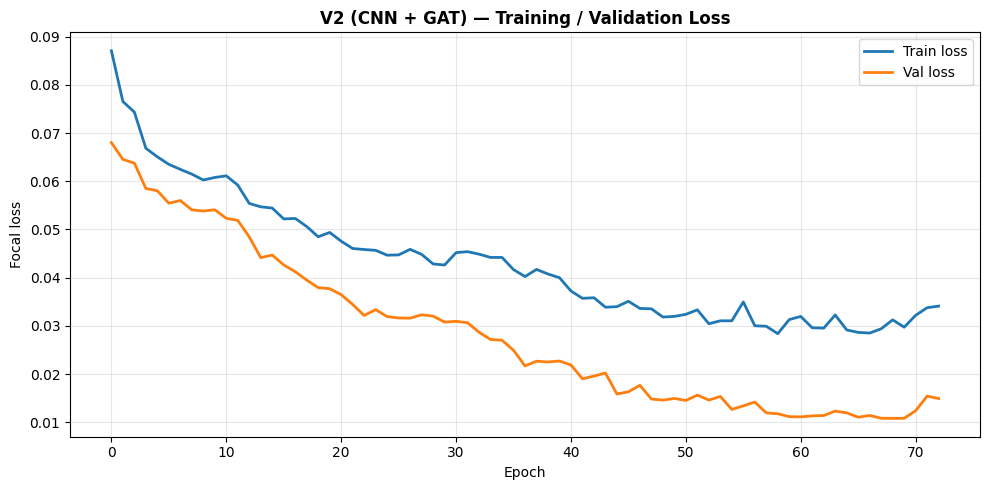

Saved: <repo>/results\Ablation_V2\V2_Loss_Curve.png


In [9]:
plt.figure(figsize=(10,5))
plt.plot(history['train_loss'], label='Train loss', linewidth=2)
plt.plot(history['val_loss'],   label='Val loss',   linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('Focal loss')
plt.title('V2 (CNN + GAT) — Training / Validation Loss', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V2_Loss_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7B — Training Accuracy Curve

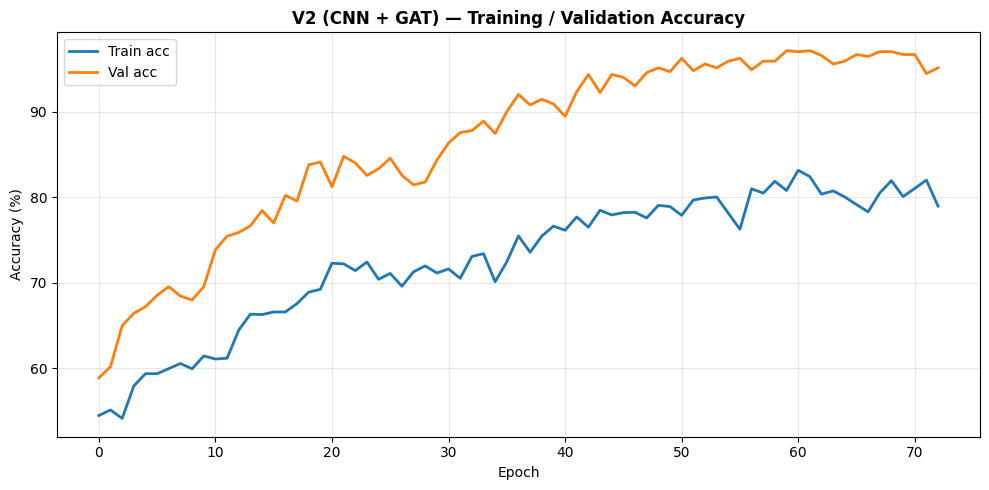

Saved: <repo>/results\Ablation_V2\V2_Accuracy_Curve.png


In [10]:
plt.figure(figsize=(10,5))
plt.plot([a*100 for a in history['train_acc']], label='Train acc', linewidth=2)
plt.plot([a*100 for a in history['val_acc']],   label='Val acc',   linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('Accuracy (%)')
plt.title('V2 (CNN + GAT) — Training / Validation Accuracy', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V2_Accuracy_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7C — Validation AUC-ROC Curve

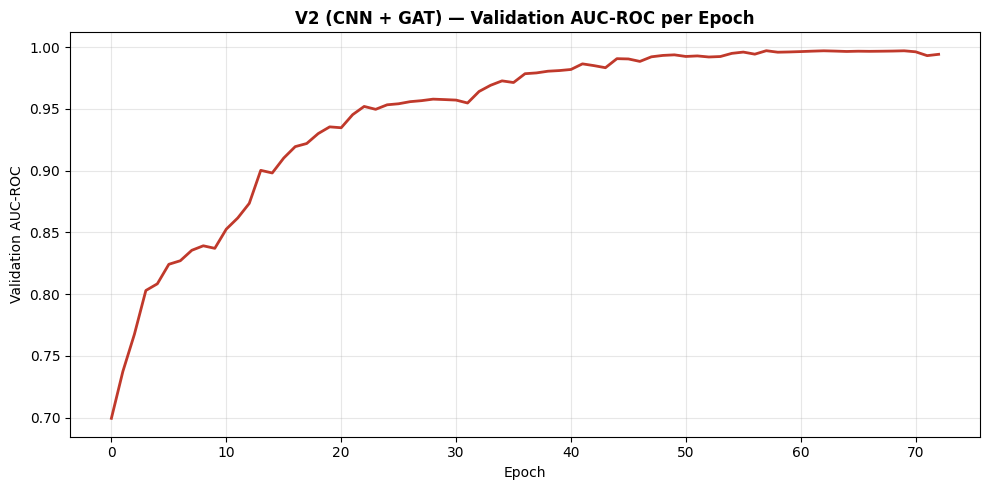

Saved: <repo>/results\Ablation_V2\V2_Validation_AUC_Curve.png


In [11]:
plt.figure(figsize=(10,5))
plt.plot(history['val_auc'], color='#c0392b', linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('Validation AUC-ROC')
plt.title('V2 (CNN + GAT) — Validation AUC-ROC per Epoch', fontweight='bold')
plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V2_Validation_AUC_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7D — Confusion Matrix (TTA×5)

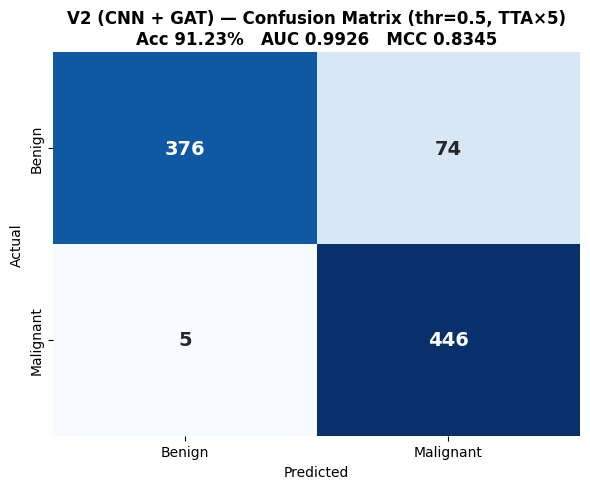

Saved: <repo>/results\Ablation_V2\V2_Confusion_Matrix.png


In [12]:
cm = confusion_matrix(all_labels_test, all_preds_test)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar=False, annot_kws={'size':14, 'weight':'bold'})
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title(f'V2 (CNN + GAT) — Confusion Matrix (thr=0.5, TTA×5)\n'
          f'Acc {acc_tta*100:.2f}%   AUC {auc_tta:.4f}   MCC {mcc_tta:.4f}',
          fontweight='bold')
plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V2_Confusion_Matrix.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7E — ROC Curve

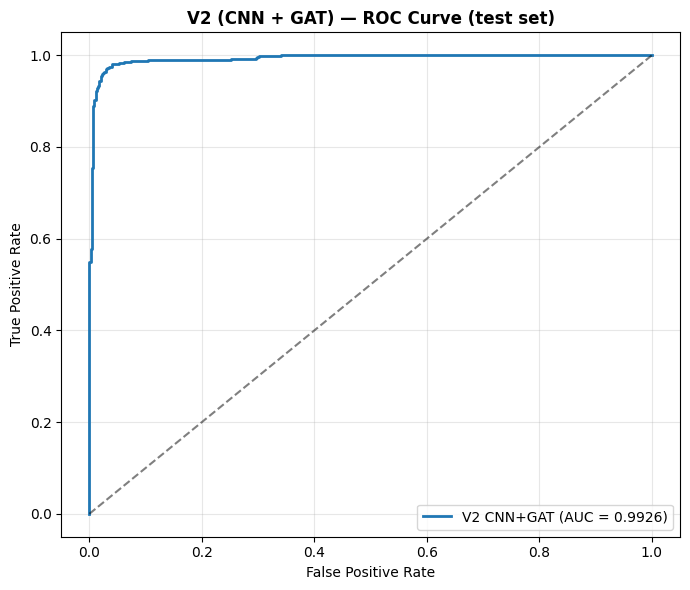

Saved: <repo>/results\Ablation_V2\V2_ROC_Curve.png


In [13]:
plt.figure(figsize=(7,6))
plt.plot(v2_fpr_saved, v2_tpr_saved, lw=2, label=f'V2 CNN+GAT (AUC = {v2_auc_saved:.4f})')
plt.plot([0,1],[0,1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('V2 (CNN + GAT) — ROC Curve (test set)', fontweight='bold')
plt.legend(loc='lower right'); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V2_ROC_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 7F — Precision-Recall Curve

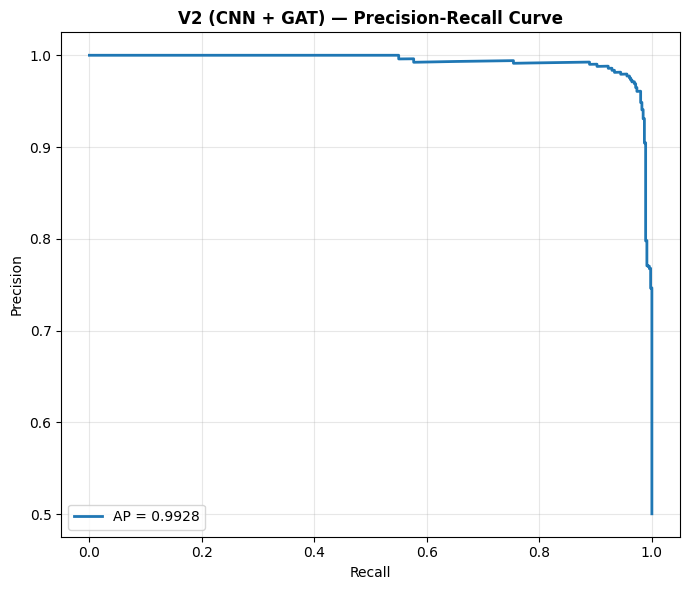

Saved: <repo>/results\Ablation_V2\V2_PR_Curve.png


In [14]:
prec, rec, _ = precision_recall_curve(all_labels_test, all_probs_test)
ap = average_precision_score(all_labels_test, all_probs_test)
plt.figure(figsize=(7,6))
plt.plot(rec, prec, lw=2, label=f'AP = {ap:.4f}')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('V2 (CNN + GAT) — Precision-Recall Curve', fontweight='bold')
plt.legend(loc='lower left'); plt.grid(alpha=0.3); plt.tight_layout()
save_p = os.path.join(CONFIG['output_dir'], 'V2_PR_Curve.png')
plt.savefig(save_p, dpi=600, bbox_inches='tight'); plt.show()
print('Saved:', save_p)


## CELL 8 — Final Performance Summary

In [15]:
print('=' * 60)
print(f'  V2 (CNN + GAT) — Final Performance')
print('=' * 60)
print(f'  Test accuracy (TTA×5) : {acc_tta*100:.2f}%')
print(f'  Test AUC-ROC          : {auc_tta:.4f}')
print(f'  MCC                   : {mcc_tta:.4f}')
print(f'  F1                    : {f1_tta:.4f}')
print(f'  Sensitivity           : {sens_tta*100:.2f}%')
print(f'  Specificity           : {spec_tta*100:.2f}%')
print(f'  Best val AUC (epoch)  : {ckpt["best_auc"]:.4f}  (epoch {ckpt["epoch"]})')
print()
print('  Design summary:')
print(f'    Backbone         : EfficientNet-B4 (blocks 0-4 frozen, 5-7 tuned)')
print(f'    CNN proj dim     : {CONFIG["cnn_proj_dim"]}')
print(f'    GAT branch       : 2 layers × {CONFIG["gat_heads"]} heads, hidden {CONFIG["gat_hidden_dim"]}')
print(f'    GCN branch       : NONE')
print(f'    Fusion           : concat 512 + 256 = 768  (NO SE gate)')
print(f'    Head hidden dim  : {CONFIG["head_hidden_dim"]}')
print(f'    Epochs / patience: {CONFIG["num_epochs"]} / {CONFIG["patience"]}   (matched)')
print()
print('  All plots saved as PNG (600 DPI) in:', CONFIG['output_dir'])
print('=' * 60)


  V2 (CNN + GAT) — Final Performance
  Test accuracy (TTA×5) : 91.23%
  Test AUC-ROC          : 0.9926
  MCC                   : 0.8345
  F1                    : 0.9186
  Sensitivity           : 98.89%
  Specificity           : 83.56%
  Best val AUC (epoch)  : 0.9972  (epoch 58)

  Design summary:
    Backbone         : EfficientNet-B4 (blocks 0-4 frozen, 5-7 tuned)
    CNN proj dim     : 512
    GAT branch       : 2 layers × 4 heads, hidden 256
    GCN branch       : NONE
    Fusion           : concat 512 + 256 = 768  (NO SE gate)
    Head hidden dim  : 128
    Epochs / patience: 80 / 15   (matched)

  All plots saved as PNG (600 DPI) in: <repo>/results\Ablation_V2
